<a href="https://colab.research.google.com/github/Kkurzo/-labs/blob/main/%22%D0%9B%D0%A0_6_%D0%9A%D0%BB%D0%B0%D1%81%D0%B8%D1%84%D1%96%D0%BA%D0%B0%D1%86%D1%96%D1%8F_%D1%82%D0%B0_%D0%BF%D0%B5%D1%80%D0%B5%D0%BD%D0%B0%D0%B2%D1%87%D0%B0%D0%BD%D0%BD%D1%8F_%D1%88%D0%B0%D0%B1%D0%BB%D0%BE%D0%BD_26_%D0%9C%D0%B5%D0%BB%D1%8C%D0%BD%D0%B8%D1%87%D1%83%D0%BA_%D0%94%D0%BC%D0%B8%D1%82%D1%80%D0%BE_%D0%A4%D0%86%D0%A2_4_10_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [31]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [32]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [33]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [34]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [35]:
# TODO: підрахуйте частоти категорій у gender.
print("Розподіл gender:")
print(df['gender'].value_counts())

Розподіл gender:
gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [36]:
# TODO: підрахуйте частоти категорій у smoking_history.
print("\nРозподіл smoking_history:")
print(df['smoking_history'].value_counts())



Розподіл smoking_history:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [37]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [38]:
# TODO: df.dtypes
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [39]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.


У датасеті спостерігається дисбаланс класів. Кількість людей без діабету значно перевищує кількість людей із діабетом.

Перевірити наявність пропущених даних


In [40]:
# TODO: df.isnull().sum()
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [41]:
# TODO: df.duplicated().sum()
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [42]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [43]:
# TODO: df
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [44]:
# TODO: df['diabetes'].value_counts()
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


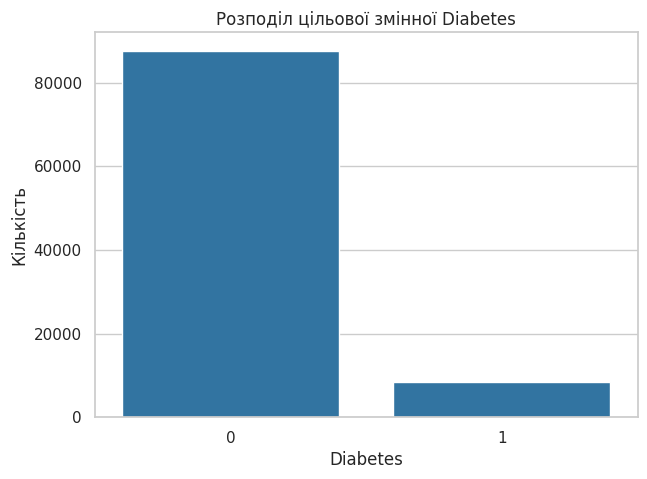

In [45]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.figure(figsize=(7, 5))

sns.countplot(x='diabetes', data=df, color='tab:blue')

plt.title('Розподіл цільової змінної Diabetes')
plt.xlabel('Diabetes')
plt.ylabel('Кількість')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [46]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [47]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X = df.drop('diabetes', axis=1)
y = df['diabetes']
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)

print("\nРозмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

Розмір X_train: (76916, 8)
Розмір X_test: (19230, 8)

Розмір y_train: (76916,)
Розмір y_test: (19230,)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [48]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).
X_train = pd.get_dummies(
    X_train,
    columns=['gender', 'smoking_history'],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=['gender', 'smoking_history'],
    dtype=int
)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print("Навчальна вибірка:")
display(X_train.head())

print("Тестова вибірка:")
display(X_test.head())

Навчальна вибірка:


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
79000,45.0,0,0,23.87,5.7,126,0,1,0,1,0,0,0,0,0
32011,64.0,0,0,33.03,4.0,126,1,0,0,0,0,0,1,0,0
95559,45.0,0,0,27.32,6.6,126,1,0,0,1,0,0,0,0,0
32057,44.0,1,0,28.86,4.8,80,0,1,0,1,0,0,0,0,0
97797,27.0,0,0,26.48,6.5,200,1,0,0,0,0,0,0,0,1


Тестова вибірка:


,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
82004,51.0,0,0,36.77,6.6,159,1,0,0,0,1,0,0,0,0
10542,12.0,0,0,22.29,4.5,90,0,1,0,1,0,0,0,0,0
31572,60.0,1,0,34.24,6.2,90,1,0,0,0,0,0,1,0,0
98055,80.0,0,0,24.39,4.0,100,0,1,0,0,0,0,1,0,0
49107,80.0,0,1,35.00,4.5,145,0,1,0,1,0,0,0,0,0


In [49]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [50]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
train_data = X_train.copy()
train_data['diabetes'] = y_train

correlation_target = train_data.corr()['diabetes'].sort_values(
    ascending=False
)

print("Кореляція ознак із diabetes:")
display(correlation_target)

Кореляція ознак із diabetes:


,diabetes
diabetes,1.000000
blood_glucose_level,0.423011
HbA1c_level,0.405321
age,0.266649
bmi,0.213456
hypertension,0.199069
heart_disease,0.174470
smoking_history_former,0.096162
gender_Male,0.040650
smoking_history_never,0.025725


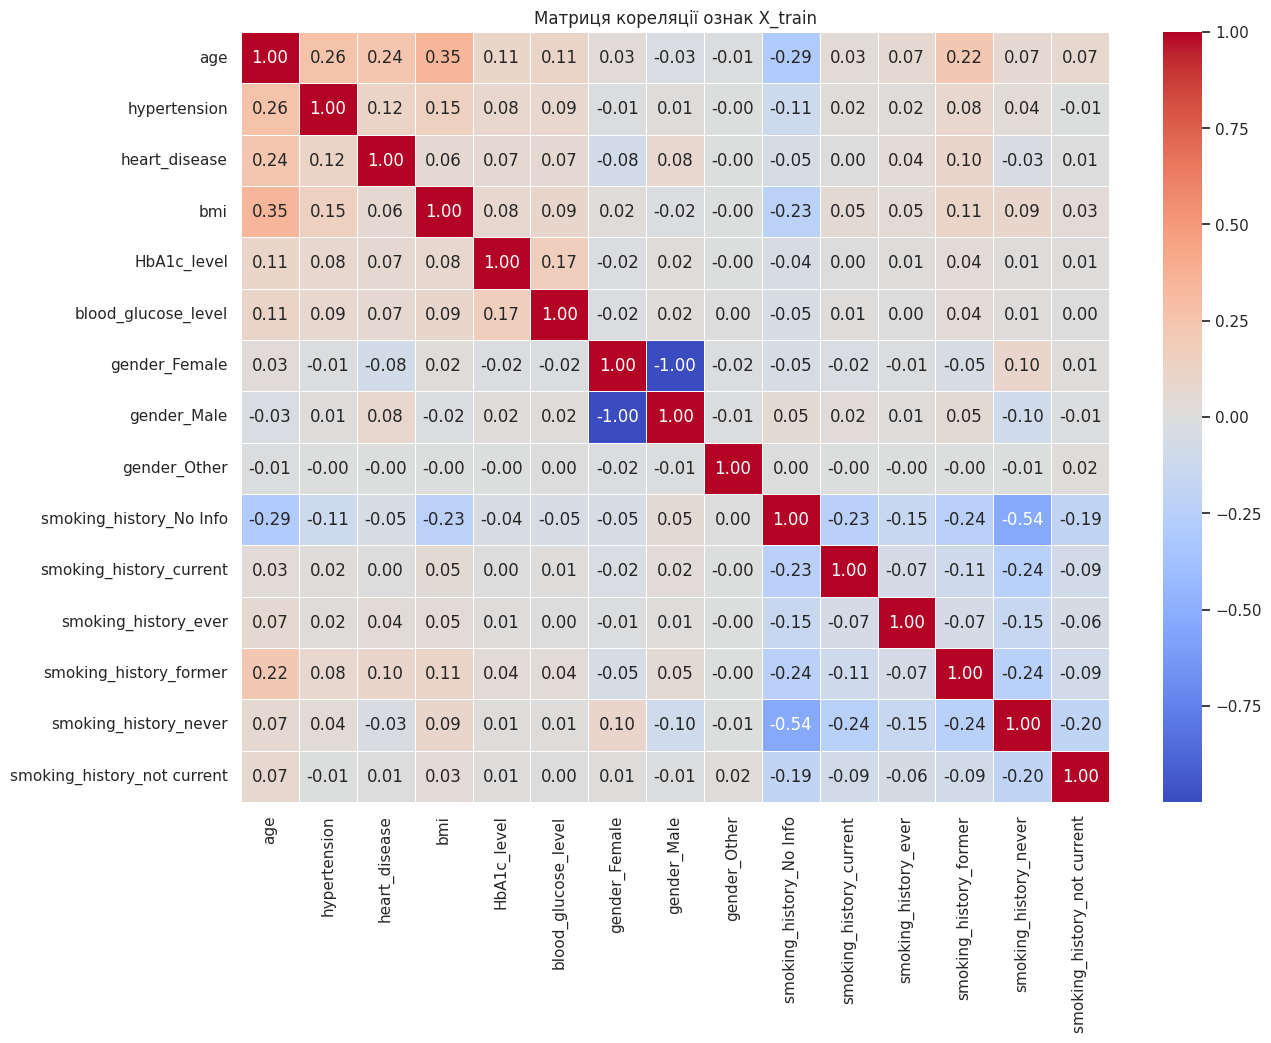

In [51]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
correlation_matrix = X_train.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Матриця кореляції ознак X_train')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

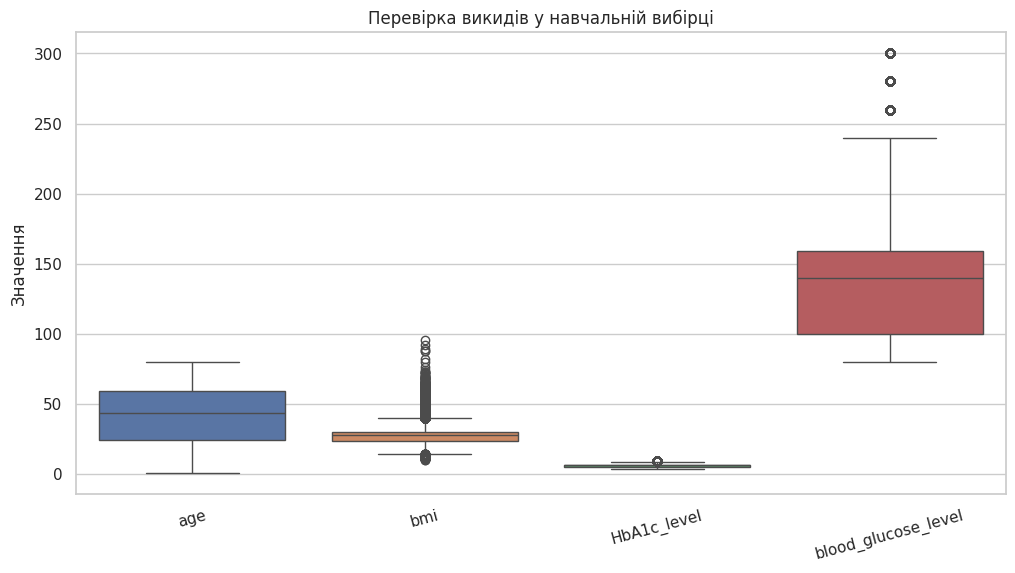

In [52]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = [
    'age',
    'bmi',
    'HbA1c_level',
    'blood_glucose_level'
]
plt.figure(figsize=(12, 6))

sns.boxplot(data=X_train[continuous_cols])

plt.title('Перевірка викидів у навчальній вибірці')
plt.ylabel('Значення')
plt.xticks(rotation=15)
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [53]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Нижня межа:", lower_bound)
print("Верхня межа:", upper_bound)

Q1: 23.39
Q3: 29.85
IQR: 6.460000000000001
Нижня межа: 13.7
Верхня межа: 39.540000000000006


Перевірити асиметрію розподілів ознак **на train**

In [54]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
skewness = X_train[continuous_cols].skew()

print("Асиметрія розподілів:")
display(skewness)

Асиметрія розподілів:


,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [55]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропущені значення X_train:")
print(X_train.isnull().sum())
print("\nПропущені значення X_test:")
print(X_test.isnull().sum())

Пропущені значення X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропущені значення X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [56]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір масштабованої X_train:", X_train_scaled.shape)
print("Розмір масштабованої X_test:", X_test_scaled.shape)

Розмір масштабованої X_train: (76916, 15)
Розмір масштабованої X_test: (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [57]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
print("До балансування:")
print(y_train.value_counts())
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled,
    y_train
)
print("\nПісля балансування:")
print(pd.Series(y_train_resampled).value_counts())

До балансування:
diabetes
0    70130
1     6786
Name: count, dtype: int64

Після балансування:
diabetes
0    70130
1    70130
Name: count, dtype: int64


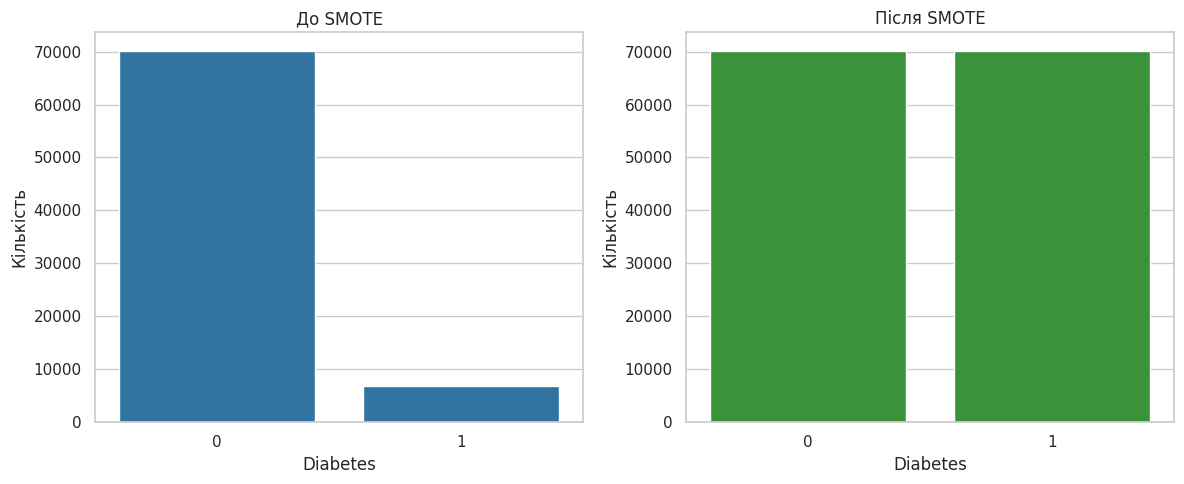

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.countplot(x=y_train, ax=axes[0], color='tab:blue')
axes[0].set_title('До SMOTE')
axes[0].set_xlabel('Diabetes')
axes[0].set_ylabel('Кількість')

sns.countplot(x=y_train_resampled, ax=axes[1], color='tab:green')
axes[1].set_title('Після SMOTE')
axes[1].set_xlabel('Diabetes')
axes[1].set_ylabel('Кількість')

plt.tight_layout()
plt.show()

Оголошуємо моделі

In [59]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.
models = {
    'LogisticRegression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'RidgeClassifier': RidgeClassifier(),

    'SGDClassifier': SGDClassifier(
        max_iter=1000,
        random_state=42
    ),

    'SVC': SVC()
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: LogisticRegression

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



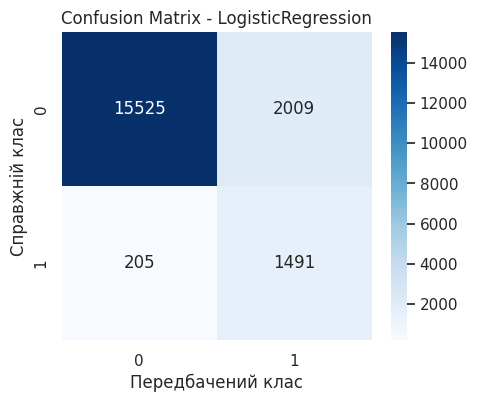


Модель: RidgeClassifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



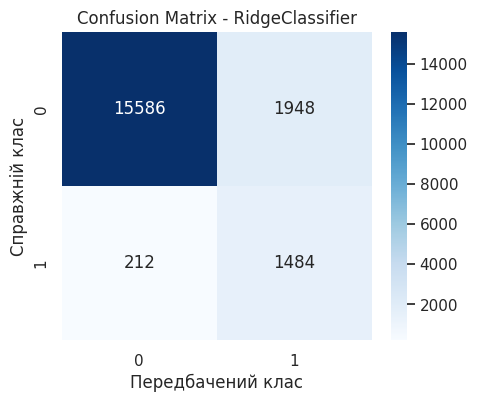


Модель: SGDClassifier

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.54      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



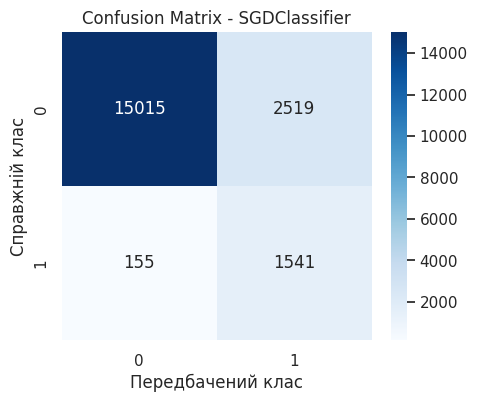


Модель: SVC

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



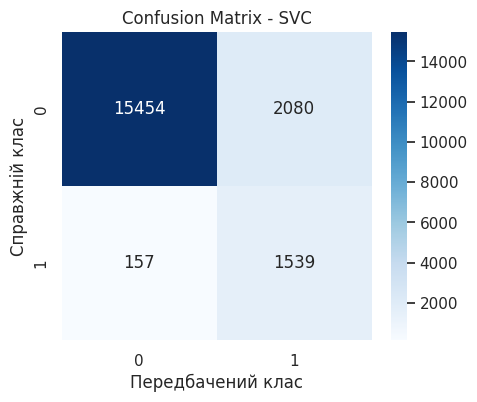

In [60]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).
results = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print("Модель:", name)

    model.fit(X_train_resampled, y_train_resampled)

    y_pred = model.predict(X_test_scaled)

    results[name] = y_pred

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )

    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Передбачений клас')
    plt.ylabel('Справжній клас')
    plt.show()

Оптимізувати гіперпараметри


In [61]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.
param_grids = {

    'LogisticRegression': {
        'model__C': [0.01, 0.1, 1, 10],
        'model__solver': ['lbfgs', 'liblinear']
    },

    'RidgeClassifier': {
        'model__alpha': [0.01, 0.1, 1, 10, 100]
    },

    'SGDClassifier': {
        'model__loss': ['hinge', 'log_loss'],
        'model__penalty': ['l2', 'l1'],
        'model__alpha': [0.0001, 0.001, 0.01]
    },

    'SVC': {
        'model__C': [0.1, 1, 10],
        'model__kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [62]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [63]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.
param_grids = {

    'LogisticRegression': {
        'model__C': [0.01, 0.1, 1, 10],
        'model__solver': ['lbfgs', 'liblinear']
    },

    'RidgeClassifier': {
        'model__alpha': [0.01, 0.1, 1, 10, 100]
    },

    'SGDClassifier': {
        'model__loss': ['hinge', 'log_loss'],
        'model__penalty': ['l2', 'l1'],
        'model__alpha': [0.0001, 0.001, 0.01]
    },

    'SVC': {
        'model__C': [0.1, 1, 10],
        'model__kernel': ['linear', 'rbf']
    }
}


Оптимізація моделі: LogisticRegression
n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 9
min_resources_: 300
max_resources_: 76916
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 8
n_resources: 300
Fitting 3 folds for each of 8 candidates, totalling 24 fits
----------
iter: 1
n_candidates: 4
n_resources: 600
Fitting 3 folds for each of 4 candidates, totalling 12 fits
----------
iter: 2
n_candidates: 2
n_resources: 1200
Fitting 3 folds for each of 2 candidates, totalling 6 fits
----------
iter: 3
n_candidates: 1
n_resources: 2400
Fitting 3 folds for each of 1 candidates, totalling 3 fits

Найкращі параметри:
{'model__C': 10, 'model__solver': 'liblinear'}

Найкращий F1-score на кросвалідації:
0.5980532124721978

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     192

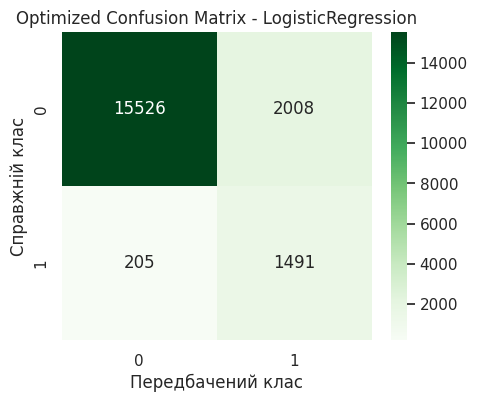


Оптимізація моделі: RidgeClassifier
n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 9
min_resources_: 300
max_resources_: 76916
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 5
n_resources: 300
Fitting 3 folds for each of 5 candidates, totalling 15 fits
----------
iter: 1
n_candidates: 3
n_resources: 600
Fitting 3 folds for each of 3 candidates, totalling 9 fits
----------
iter: 2
n_candidates: 2
n_resources: 1200
Fitting 3 folds for each of 2 candidates, totalling 6 fits

Найкращі параметри:
{'model__alpha': 1}

Найкращий F1-score на кросвалідації:
0.5028158631873803

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



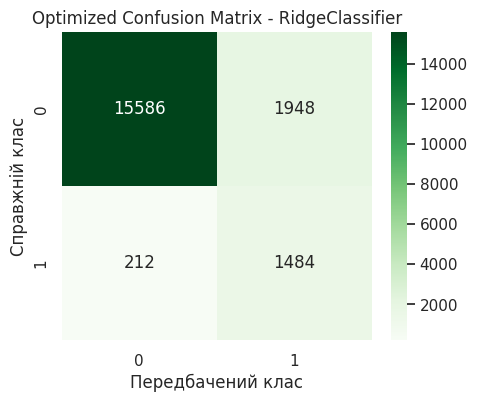


Оптимізація моделі: SGDClassifier
n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 9
min_resources_: 300
max_resources_: 76916
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 12
n_resources: 300
Fitting 3 folds for each of 12 candidates, totalling 36 fits
----------
iter: 1
n_candidates: 6
n_resources: 600
Fitting 3 folds for each of 6 candidates, totalling 18 fits
----------
iter: 2
n_candidates: 3
n_resources: 1200
Fitting 3 folds for each of 3 candidates, totalling 9 fits
----------
iter: 3
n_candidates: 2
n_resources: 2400
Fitting 3 folds for each of 2 candidates, totalling 6 fits

Найкращі параметри:
{'model__alpha': 0.001, 'model__loss': 'log_loss', 'model__penalty': 'l2'}

Найкращий F1-score на кросвалідації:
0.5741600942221657

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.57      1696

    accuracy              

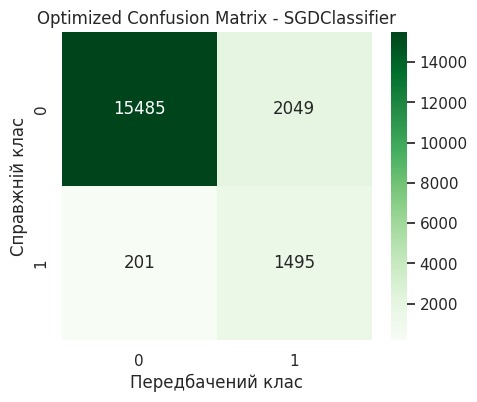


Оптимізація моделі: SVC
n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 9
min_resources_: 300
max_resources_: 76916
aggressive_elimination: False
factor: 2
----------
iter: 0
n_candidates: 6
n_resources: 300
Fitting 3 folds for each of 6 candidates, totalling 18 fits
----------
iter: 1
n_candidates: 3
n_resources: 600
Fitting 3 folds for each of 3 candidates, totalling 9 fits
----------
iter: 2
n_candidates: 2
n_resources: 1200
Fitting 3 folds for each of 2 candidates, totalling 6 fits

Найкращі параметри:
{'model__C': 1, 'model__kernel': 'linear'}

Найкращий F1-score на кросвалідації:
0.6031056233856813

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.89      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



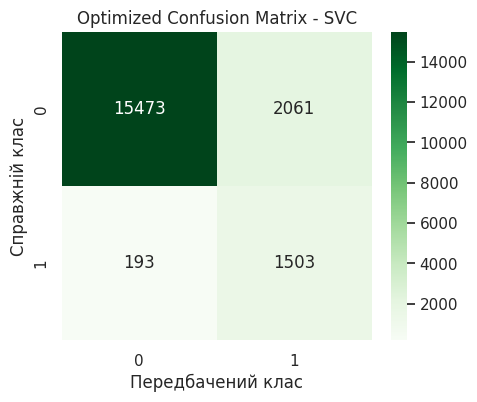

In [64]:
best_models = {}
best_scores = {}

for name, model in models.items():

    print("\n" + "=" * 60)
    print("Оптимізація моделі:", name)

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=2,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("\nНайкращі параметри:")
    print(search.best_params_)

    print("\nНайкращий F1-score на кросвалідації:")
    print(search.best_score_)

    y_pred_best = search.best_estimator_.predict(X_test)

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred_best))

    cm = confusion_matrix(y_test, y_pred_best)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Greens'
    )

    plt.title(f'Optimized Confusion Matrix - {name}')
    plt.xlabel('Передбачений клас')
    plt.ylabel('Справжній клас')
    plt.show()

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [65]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.
scores_df = pd.DataFrame({
    'Модель': list(best_scores.keys()),
    'F1-score (CV)': list(best_scores.values())
})

scores_df = scores_df.sort_values(
    by='F1-score (CV)',
    ascending=False
)

display(scores_df)
best_model_name = max(best_scores, key=best_scores.get)

best_model = best_models[best_model_name]

print("Найкраща модель:", best_model_name)
print("Найкращий F1-score:", best_scores[best_model_name])

,Модель,F1-score (CV)
3,SVC,0.603106
0,LogisticRegression,0.598053
2,SGDClassifier,0.574160
1,RidgeClassifier,0.502816


Найкраща модель: SVC
Найкращий F1-score: 0.6031056233856813


In [66]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.
random_indices = X_test.sample(
    n=10,
    random_state=42
).index
predictions = best_model.predict(X_test.loc[random_indices])

comparison = pd.DataFrame({
    'Індекс': random_indices,
    'Істинний клас': y_test.loc[random_indices].values,
    'Передбачений клас': predictions
})

display(comparison)

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики